In [1]:
print("Welcome to Beyond Our Solar System!")

project_name = "Exploring Distant Worlds"

project_goal = """There is an entire universe beyond our Solar System, and we still have so much to learn about it.Through this project, I want to investigate that universe and discover its hidden scientific gems. Who knows? Perhaps we could find a planet with characteristics similar to Earth's """


print(project_name)
print(project_goal)

Welcome to Beyond Our Solar System!
Exploring Distant Worlds
There is an entire universe beyond our Solar System, and we still have so much to learn about it.Through this project, I want to investigate that universe and discover its hidden scientific gems. Who knows? Perhaps we could find a planet with characteristics similar to Earth's 


In [2]:
planet_radius = 1.0

if planet_radius >= 0.8 and planet_radius <= 1.2:
    print("Passes the radius test")
else:
    print("Outside the radius range")

Passes the radius test


In [3]:
planet_radii = [0.7, 1.0, 1.3]

for radius in planet_radii:
    print(radius)

0.7
1.0
1.3


In [4]:
for radius in planet_radii:
    if radius >= 0.8 and radius <= 1.2:
        print("Passes the radius test")
    else:
        print("Outside the radius range")

Outside the radius range
Passes the radius test
Outside the radius range


In [5]:
planets = [("Planet A", 0.7),("Planet B", 1.0),("Planet C", 1.3)]


for name, radius in planets:
    if radius >= 0.8 and radius <= 1.2:
        print(name, "passes the radius test")
    else:
        print(name, "is outside the radius range")

Planet A is outside the radius range
Planet B passes the radius test
Planet C is outside the radius range


In [6]:
import pandas as pd

example_data = {"planet": ["Planet A", "Planet B", "Planet C"],"radius_earth": [0.7, 1.0, 1.3]}

df = pd.DataFrame(example_data)
df.head()

,planet,radius_earth
0,Planet A,0.7
1,Planet B,1.0
2,Planet C,1.3


PLANETS EXPLORER
Searching for confirmed exoplanets with
radii between 0.8 and 1.2 Earth radii.

DATASET OVERVIEW
Number of records: 6401
Available columns: ['pl_name', 'hostname', 'pl_rade', 'pl_orbper', 'pl_eqt', 'disc_year']

First five rows:
          pl_name      hostname  pl_rade  pl_orbper  pl_eqt  disc_year
0     Kepler-37 b     Kepler-37   0.3098  13.367020   718.0       2013
1  PSR B1257+12 b  PSR B1257+12   0.3380  25.262000     NaN       1994
2     Kepler-37 e     Kepler-37   0.3700  51.196000   401.0       2014
3    Kepler-879 c    Kepler-879   0.4000   0.646716     NaN       2024
4    Kepler-444 b    Kepler-444   0.4030   3.600105   938.0       2015

Records with usable radius measurements: 6401

RESEARCH RESULTS
Planets within our radius range: 419

First 20 matching planets:
      pl_name    hostname  pl_rade  pl_orbper  pl_eqt  disc_year
Kepler-1076 b Kepler-1076  0.80000   6.147279   770.0       2016
Kepler-1395 b Kepler-1395  0.80000   3.784706  1311.0       2016
Kep

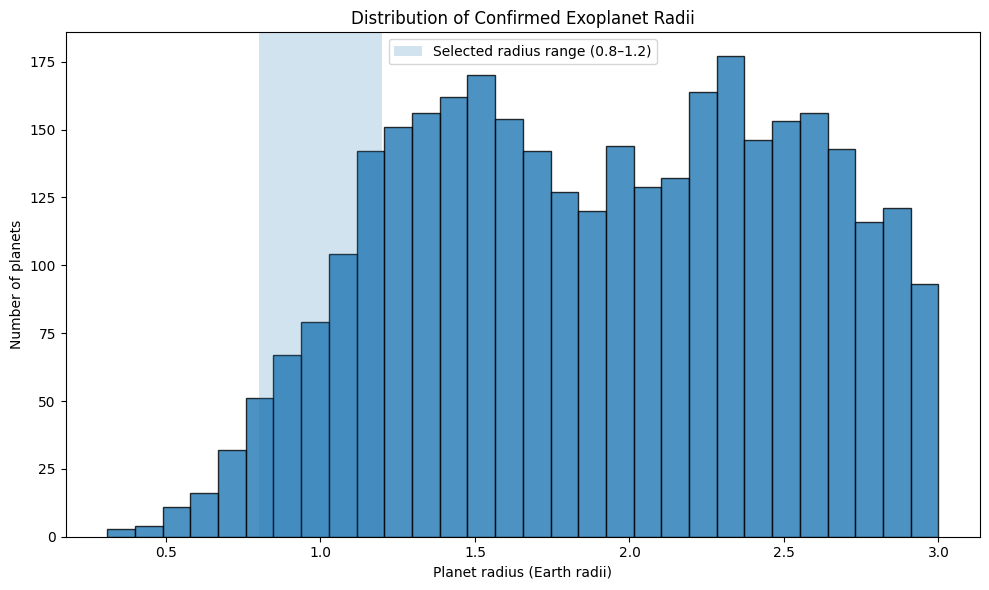


Analysis complete.
Results saved to: earth_sized_exoplanets.csv

SCIENTIFIC LIMITATION
A similar radius does not prove that a planet is habitable. Atmosphere, temperature, composition, and orbital conditions require separate investigation.


In [7]:

# ============================================================
# PLANETS EXPLORER — BEYOND OUR SOLAR SYSTEM
# Research question:
# How many confirmed exoplanets have radii similar to Earth's?
# Data source: NASA Exoplanet Archive
# ============================================================

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import requests
from io import StringIO

# 2. Define our research criteria
LOWER_RADIUS = 0.8
UPPER_RADIUS = 1.2

print("PLANETS EXPLORER")
print("Searching for confirmed exoplanets with")
print(f"radii between {LOWER_RADIUS} and {UPPER_RADIUS} Earth radii.")
print()

# 3. Retrieve real exoplanet data from NASA
url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"

query = """
SELECT pl_name, hostname, pl_rade, pl_orbper, pl_eqt, disc_year
FROM pscomppars
WHERE pl_rade IS NOT NULL
ORDER BY pl_rade
"""

response = requests.get(
    url,
    params={"query": query, "format": "csv"},
    timeout=60
)

response.raise_for_status()

df = pd.read_csv(StringIO(response.text))

# 4. Inspect the dataset
print("DATASET OVERVIEW")
print("Number of records:", len(df))
print("Available columns:", df.columns.tolist())
print()
print("First five rows:")
print(df.head())

# 5. Prepare the data
# Convert relevant columns to numeric values.
for column in ["pl_rade", "pl_orbper", "pl_eqt", "disc_year"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Remove rows without a usable planet radius.
df = df.dropna(subset=["pl_rade"])

print()
print("Records with usable radius measurements:", len(df))

# 6. Filter for planets within our chosen radius range
earth_like_planets = df[
    (df["pl_rade"] >= LOWER_RADIUS) &
    (df["pl_rade"] <= UPPER_RADIUS)
].copy()

# Sort from smallest to largest radius.
earth_like_planets = earth_like_planets.sort_values("pl_rade")

# 7. Display the findings
count = len(earth_like_planets)

print()
print("=" * 55)
print("RESEARCH RESULTS")
print("=" * 55)
print(f"Planets within our radius range: {count}")
print()
print("First 20 matching planets:")

print(
    earth_like_planets[
        ["pl_name", "hostname", "pl_rade",
         "pl_orbper", "pl_eqt", "disc_year"]
    ].head(20).to_string(index=False)
)

# 8. Visualize the distribution of planet sizes
# Focus the graph on radii up to 3 Earth radii so the
# selected range is easier to see.
plot_data = df.loc[df["pl_rade"] <= 3, "pl_rade"]

plt.figure(figsize=(10, 6))

plt.hist(
    plot_data,
    bins=30,
    edgecolor="black",
    alpha=0.8
)

plt.axvspan(
    LOWER_RADIUS,
    UPPER_RADIUS,
    alpha=0.2,
    label="Selected radius range (0.8–1.2)"
)

plt.xlabel("Planet radius (Earth radii)")
plt.ylabel("Number of planets")
plt.title("Distribution of Confirmed Exoplanet Radii")
plt.legend()
plt.tight_layout()
plt.show()

# 9. Save our results to a CSV file
output_file = "earth_sized_exoplanets.csv"

earth_like_planets.to_csv(output_file, index=False)

print()
print("Analysis complete.")
print("Results saved to:", output_file)

# 10. State the scientific limitation
print()
print("SCIENTIFIC LIMITATION")
print(
    "A similar radius does not prove that a planet is habitable. "
    "Atmosphere, temperature, composition, and orbital conditions "
    "require separate investigation."
)
